# Clima de la Tierra, la Luna y Marte (v1)
**NASA Space Apps Challenge 2026** · Capa de clima para comparar cada sitio de la Luna y de Marte con las regiones candidatas y los análogos conocidos de la Tierra.

| Lado | Datos | Qué se mide |
|---|---|---|
| Tierra | **MODIS Aqua `MYD11C3` v061** (temperatura de la superficie, mensual, 0,05° ≈ 5,6 km), 2014–2023 | superficie de día (13:30) y de noche (01:30) |
| Marte | MACDA v2.0 (ya calculado en `clima_v0`) | temperatura de la superficie cada 2 h, celdas de 5° |
| Luna | **LRO Diviner GCP** (Williams et al. 2017, 0,5°, 96 horas locales) + **PRP** (Paige et al. 2010) en el polo sur | temperatura de la superficie a lo largo del día lunar; hielo estable bajo la superficie |

**Cambios respecto a v0**
1. **Superficie contra superficie.** v0 comparaba el aire a 2 m de la Tierra (MERRA-2) con la superficie de Marte. v1 usa la temperatura de la superficie en los tres cuerpos.
2. **Escala.** MERRA-2 daba ~50 km por celda; MODIS da ~5,6 km, así que un análogo pequeño (Haughton, Río Tinto, Mauna Kea) ya no recibe el clima de una celda enorme y no hace falta corregir por altitud.
3. **La Luna entra.** No tiene atmósfera, pero sí un ambiente térmico extremo que condiciona la base (materiales, energía, ciclos día/noche). Se compara con Diviner.
4. **Percentiles frente a todo el planeta.** El percentil de cada lugar de la Tierra se calcula frente a toda la tierra emergida (rejilla de 0,5°, ponderada por área), no solo frente a los 56 lugares.
5. **Dónde falla la analogía.** Junto a la distancia relativa se guarda la diferencia absoluta en °C de cada medida (lo que pide la ficha del reto).

**Por tandas**: se guarda cada mes de MODIS y cada banda de Diviner en Drive y cada ejecución se para a los `MAX_MINUTOS`. **Si al final pone «⏸ Quedan…», vuelve a ejecutar el notebook**: sigue donde lo dejó.

## 0. Instalación

In [27]:
!pip install -q earthaccess pyhdf

## 1. Configuración

In [28]:
import os, re, gc, io, json, time, glob, math, datetime, unicodedata
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import earthaccess
from shapely import contains_xy
from shapely.geometry import shape, Point
from shapely import affinity
from IPython.display import display
from google.colab import drive, userdata

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "clima_v1"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE_LST = f"{BASE}/03_datos/cache_api/clima/modis_lst"
CACHE_DIV = f"{BASE}/03_datos/cache_api/clima/diviner"
TMP = "/content/tmp/clima_v1"
FIGURAS = f"{RES}/figuras"
for d in (RES, WEB, CACHE_LST, CACHE_DIV, TMP, FIGURAS):
    os.makedirs(d, exist_ok=True)

MAX_MINUTOS = 40                  # tiempo máximo por ejecución (vuelve a ejecutar para seguir)
ANIOS = range(2014, 2024)         # mismo periodo que clima_v0 y el índice de Marte v1.3
PRODUCTO_LST, VERSION_LST = "MYD11C3", "061"   # Aqua: pasa a las 13:30 (cerca de la máxima) y a la 01:30
PASO_REF = 10                     # rejilla de referencia de la Tierra: bloques de 10×10 celdas = 0,5°
MIN_MESES = 9                     # meses de la climatología con dato para aceptar un lugar o una celda
RADIO_ANALOGO_KM = 10             # igual que topografia_v1 y clima_v0
RADIO_SITIO_LUNA_KM = 15          # Diviner GCP tiene celdas de 0,5° (~15 km en latitud)
R_LUNA_KM = 1737.4
UMBRAL_PARECIDO = 0.2
MEDIDAS = {
    "marte": ["ts_media", "ts_min", "amplitud_anual", "osc_diaria"],   # las mismas 4 que v0
    "luna":  ["ts_media", "ts_min", "ts_max", "osc_diaria"],           # la Luna casi no tiene estaciones: máxima en lugar de amplitud anual
}
CLIMA_V0 = f"{BASE}/04_resultados/clima_v0"
TOPO_SITIOS = f"{BASE}/04_resultados/topografia_sitios_v2/similitud_sitio_tierra.csv"
T0 = time.time()
minutos = lambda: (time.time() - T0) / 60

_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
auth = earthaccess.login(strategy="environment")
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
print("Earthdata:", auth.authenticated)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earthdata: True


## 2. Tierra: regiones candidatas y análogos conocidos
Los mismos 56 lugares que en `clima_v0` (mismos `region_id`). Cada uno se asigna a las celdas de MODIS (0,05°) cuyo centro cae dentro; los análogos usan un círculo de 10 km.

In [29]:
def circulo_grados(lon, lat, radio_km):
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

filas = []
for cuerpo in ["luna", "marte"]:
    info = entrada["cuerpos"][cuerpo]
    for ft in json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))["features"]:
        p = ft["properties"]
        filas.append({"region_id": p["id"], "cuerpo": cuerpo, "tipo": "region_candidata", "region": p.get("region"), "geom": shape(ft["geometry"])})
    for ft in json.load(open(f"{BASE}/06_web/{info['carpeta']}/analogos.geojson", encoding="utf-8"))["features"]:
        p = ft["properties"]
        ok = (p.get("tipo") in ("analogo_luna", "impacto")) if cuerpo == "luna" else (p.get("verificacion") == "verificada")
        if not ok or not ft.get("geometry"):
            continue
        lon, lat = ft["geometry"]["coordinates"][:2]
        slug = re.sub(r"[^a-z0-9]+", "-", unicodedata.normalize("NFKD", p["nombre"]).encode("ascii", "ignore").decode().lower()).strip("-")[:40]
        filas.append({"region_id": f"analogo-{cuerpo}-{slug}", "cuerpo": cuerpo, "tipo": "analogo_conocido", "region": p["nombre"],
                      "geom": circulo_grados(lon, lat, RADIO_ANALOGO_KM)})
ent = pd.DataFrame(filas)

NX, NY, DG = 7200, 3600, 0.05
LON_C = -180 + DG / 2 + DG * np.arange(NX)
LAT_C = 90 - DG / 2 - DG * np.arange(NY)

def celdas_modis(geom):
    minx, miny, maxx, maxy = geom.bounds
    i0, i1 = max(int((minx + 180) / DG) - 1, 0), min(int((maxx + 180) / DG) + 2, NX)
    j0, j1 = max(int((90 - maxy) / DG) - 1, 0), min(int((90 - miny) / DG) + 2, NY)
    LL, LA = np.meshgrid(LON_C[i0:i1], LAT_C[j0:j1])
    jj, ii = np.nonzero(contains_xy(geom, LL, LA))
    if len(ii) == 0:                      # región diminuta: la celda del centroide
        c = geom.centroid
        return np.array([min(int((90 - c.y) / DG), NY - 1)]), np.array([min(int((c.x + 180) / DG), NX - 1)])
    return jj + j0, ii + i0

CELDAS = {r.region_id: celdas_modis(r.geom) for r in ent.itertuples()}
ent["n_celdas_modis"] = ent.region_id.map(lambda r: len(CELDAS[r][0]))
print(f"{len(ent)} lugares de la Tierra:", ent.groupby(["cuerpo", "tipo"]).size().to_dict())
display(ent[["region_id", "region", "n_celdas_modis"]])

56 lugares de la Tierra: {('luna', 'analogo_conocido'): 7, ('luna', 'region_candidata'): 20, ('marte', 'analogo_conocido'): 8, ('marte', 'region_candidata'): 21}


,region_id,region,n_celdas_modis
0,luna-1,"Afar, Etiopía",1721
1,luna-2,"Gobernacion de Rif Dimashq, Siria",811
2,luna-3,"Provincia de Medina, Arabia Saudita",441
3,luna-4,"Afar, Etiopía",259
4,luna-5,"Condado de Marsabit, Kenia",210
5,luna-6,"Provincia de La Meca, Arabia Saudita",181
6,luna-7,Islandia,355
7,luna-8,"Afar, Etiopía",136
8,luna-9,"Provincia de Tabuk, Arabia Saudita",149
9,luna-10,"Tibesti, Chad",139


## 3. Tierra: temperatura de la superficie MODIS (`MYD11C3`, 120 meses)
Por cada mes: se descarga el archivo (~ 50–80 MB), se extraen el día y la noche de cada lugar, se guarda en Drive un resumen de la rejilla a 0,5° (para la referencia global) y se borra el archivo.

In [30]:
def leer_lst(ruta):
    """Devuelve (día, noche) en °C, con NaN donde no hay dato."""
    try:
        from pyhdf.SD import SD, SDC
        f = SD(ruta, SDC.READ)
        dia, noche = f.select("LST_Day_CMG")[:].astype(np.float32), f.select("LST_Night_CMG")[:].astype(np.float32)
        f.end()
    except ImportError:
        from osgeo import gdal
        subs = {n.split(":")[-1]: n for n, _ in gdal.Open(ruta).GetSubDatasets()}
        dia = gdal.Open(subs["LST_Day_CMG"]).ReadAsArray().astype(np.float32)
        noche = gdal.Open(subs["LST_Night_CMG"]).ReadAsArray().astype(np.float32)
    for a in (dia, noche):
        a[a == 0] = np.nan
        a *= 0.02
        a -= 273.15
    return dia, noche

def bloques(a, k=PASO_REF):
    ny, nx = a.shape
    with np.errstate(all="ignore"):
        return np.nanmean(a.reshape(ny // k, k, nx // k, k), axis=(1, 3)).astype(np.float16)

def clave_mes(nombre):
    m = re.search(r"\.A(\d{4})(\d{3})\.", nombre)
    f = datetime.date(int(m.group(1)), 1, 1) + datetime.timedelta(days=int(m.group(2)) - 1)
    return f"{f.year}{f.month:02d}"

granulos = earthaccess.search_data(short_name=PRODUCTO_LST, version=VERSION_LST,
                                   temporal=(f"{ANIOS[0]}-01-01", f"{ANIOS[-1]}-12-31"))
por_mes = {}
for g in granulos:
    nombre = g.data_links()[0].split("/")[-1]
    por_mes.setdefault(clave_mes(nombre), g)
hechos = {os.path.basename(p)[:6] for p in glob.glob(f"{CACHE_LST}/*_lugares.json")}
pendientes = sorted(k for k in por_mes if k not in hechos)
print(f"{len(por_mes)} meses en Earthdata · ya en Drive: {len(hechos)} · pendientes: {len(pendientes)}")

for k in pendientes:
    if minutos() > MAX_MINUTOS:
        break
    try:
        ruta = str(earthaccess.download([por_mes[k]], TMP)[0])
        dia, noche = leer_lst(ruta)
    except Exception as e:
        print(f"  {k}: error ({str(e)[:120]}); se reintentará en la próxima ejecución")
        continue
    resumen = {}
    for rid, (jj, ii) in CELDAS.items():
        vd, vn = dia[jj, ii], noche[jj, ii]
        resumen[rid] = {"dia": float(np.nanmean(vd)) if np.isfinite(vd).any() else None,
                        "noche": float(np.nanmean(vn)) if np.isfinite(vn).any() else None,
                        "frac_dia": round(float(np.isfinite(vd).mean()), 3), "frac_noche": round(float(np.isfinite(vn).mean()), 3)}
    np.savez_compressed(f"{CACHE_LST}/{k}_ref.npz", dia=bloques(dia), noche=bloques(noche))
    json.dump(resumen, open(f"{CACHE_LST}/{k}_lugares.json", "w"))
    os.remove(ruta); del dia, noche; gc.collect()
    print(f"  {k} ✓  ({minutos():.0f} min)")

faltan_lst = len([k for k in por_mes if not os.path.exists(f"{CACHE_LST}/{k}_lugares.json")])
print("✅ MODIS completo." if faltan_lst == 0 else f"⏸ Quedan {faltan_lst} meses de MODIS: vuelve a ejecutar el notebook.")

120 meses en Earthdata · ya en Drive: 120 · pendientes: 0
✅ MODIS completo.


## 4. Tierra: medidas del clima de la superficie
Climatología de 12 meses (media de los 10 años de cada mes) y, a partir de ella:

| Medida | Definición |
|---|---|
| `ts_media` | media anual de (día + noche) / 2 |
| `ts_min` | noche del mes más frío |
| `ts_max` | día del mes más cálido |
| `amplitud_anual` | mes más cálido − mes más frío (media día/noche) |
| `osc_diaria` | media anual de (día − noche) |

Lo mismo para cada celda de 0,5° de la rejilla de referencia, ponderada por el área (cos lat).

/tmp/ipykernel_661/1897518477.py:38: RuntimeWarning: Mean of empty slice
  D12 = np.stack([np.nanmean([a for a, _ in acum[mm]], axis=0) for mm in range(1, 13)])
/tmp/ipykernel_661/1897518477.py:39: RuntimeWarning: Mean of empty slice
  N12 = np.stack([np.nanmean([b for _, b in acum[mm]], axis=0) for mm in range(1, 13)])
/tmp/ipykernel_661/1897518477.py:6: RuntimeWarning: Mean of empty slice
  out = {"ts_media": np.nanmean(media12, axis=0), "ts_min": np.nanmin(noche12, axis=0), "ts_max": np.nanmax(dia12, axis=0),
/tmp/ipykernel_661/1897518477.py:6: RuntimeWarning: All-NaN slice encountered
  out = {"ts_media": np.nanmean(media12, axis=0), "ts_min": np.nanmin(noche12, axis=0), "ts_max": np.nanmax(dia12, axis=0),
/tmp/ipykernel_661/1897518477.py:7: RuntimeWarning: All-NaN slice encountered
  "amplitud_anual": np.nanmax(media12, axis=0) - np.nanmin(media12, axis=0), "osc_diaria": np.nanmean(dia12 - noche12, axis=0)}
/tmp/ipykernel_661/1897518477.py:7: RuntimeWarning: Mean of empty slice
  

Celdas de referencia con clima completo: 95,977


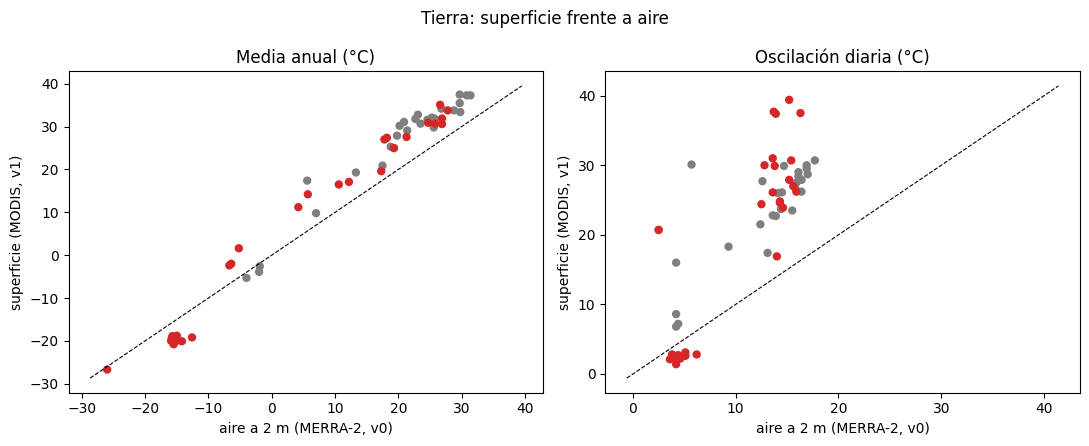

,region_id,region,ts_media,ts_min,ts_max,amplitud_anual,osc_diaria,meses_validos,frac_validas
0,luna-1,"Afar, Etiopía",37.3,22.1,52.1,6.5,22.8,12.0,1.00
1,luna-2,"Gobernacion de Rif Dimashq, Siria",25.3,1.9,55.3,27.6,26.7,12.0,1.00
2,luna-3,"Provincia de Medina, Arabia Saudita",31.6,7.5,57.4,21.0,29.0,12.0,1.00
3,luna-4,"Afar, Etiopía",37.5,20.9,53.0,5.2,26.0,12.0,1.00
4,luna-5,"Condado de Marsabit, Kenia",33.4,23.2,44.2,3.0,17.4,12.0,1.00
5,luna-6,"Provincia de La Meca, Arabia Saudita",31.9,11.2,52.9,13.7,27.9,12.0,1.00
6,luna-7,Islandia,-2.6,-11.8,18.6,20.2,8.6,12.0,1.00
7,luna-8,"Afar, Etiopía",35.5,20.2,49.8,5.2,23.7,12.0,1.00
8,luna-9,"Provincia de Tabuk, Arabia Saudita",27.9,3.3,54.9,23.2,28.4,12.0,1.00
9,luna-10,"Tibesti, Chad",30.2,6.6,50.4,14.4,29.5,12.0,1.00


In [31]:
def medidas_desde_clim(dia12, noche12):
    """dia12, noche12: arrays (12, ...) de la climatología mensual. Devuelve dict de arrays."""
    with np.errstate(all="ignore"):
        media12 = (dia12 + noche12) / 2
        validos = np.isfinite(media12).sum(axis=0)
        out = {"ts_media": np.nanmean(media12, axis=0), "ts_min": np.nanmin(noche12, axis=0), "ts_max": np.nanmax(dia12, axis=0),
               "amplitud_anual": np.nanmax(media12, axis=0) - np.nanmin(media12, axis=0), "osc_diaria": np.nanmean(dia12 - noche12, axis=0)}
    for kk in out:
        out[kk] = np.where(validos >= MIN_MESES, out[kk], np.nan)
    out["meses_validos"] = validos
    return out

if faltan_lst:
    raise SystemExit("⏸ Faltan meses de MODIS: vuelve a ejecutar el notebook.")

filas = []
for p in sorted(glob.glob(f"{CACHE_LST}/*_lugares.json")):
    k = os.path.basename(p)[:6]
    for rid, v in json.load(open(p)).items():
        filas.append({"region_id": rid, "anio": int(k[:4]), "mes": int(k[4:]), **v})
mensual = pd.DataFrame(filas)
clim = mensual.groupby(["region_id", "mes"])[["dia", "noche"]].mean().unstack("mes")
d12 = clim["dia"].reindex(columns=range(1, 13)).to_numpy().T
n12 = clim["noche"].reindex(columns=range(1, 13)).to_numpy().T
m = medidas_desde_clim(d12, n12)
tierra = ent.drop(columns="geom").set_index("region_id")
for kk, v in m.items():
    tierra.loc[clim.index, kk] = np.round(v, 1) if kk != "meses_validos" else v
tierra["frac_validas"] = mensual.groupby("region_id")[["frac_dia", "frac_noche"]].mean().mean(axis=1).round(2)
tierra = tierra.reset_index()

# Rejilla de referencia: toda la tierra emergida con dato a 0,5°
acum = {}
for p in sorted(glob.glob(f"{CACHE_LST}/*_ref.npz")):
    mes = int(os.path.basename(p)[4:6]); z = np.load(p)
    acum.setdefault(mes, []).append((z["dia"].astype(np.float32), z["noche"].astype(np.float32)))
with np.errstate(all="ignore"):
    D12 = np.stack([np.nanmean([a for a, _ in acum[mm]], axis=0) for mm in range(1, 13)])
    N12 = np.stack([np.nanmean([b for _, b in acum[mm]], axis=0) for mm in range(1, 13)])
REF = medidas_desde_clim(D12, N12)
lat_ref = 90 - (PASO_REF * DG) / 2 - PASO_REF * DG * np.arange(D12.shape[1])
W_REF = np.repeat(np.cos(np.radians(lat_ref))[:, None], D12.shape[2], axis=1)
print(f"Celdas de referencia con clima completo: {np.isfinite(REF['ts_media']).sum():,}")

# Comprobación: superficie (MODIS) frente al aire a 2 m de clima_v0 (MERRA-2)
v0 = pd.read_csv(f"{CLIMA_V0}/clima_tierra.csv")
comp = tierra.merge(v0[["region_id", "t_media", "osc_diaria"]].rename(columns={"t_media": "aire_t_media", "osc_diaria": "aire_osc_diaria"}), on="region_id", how="left")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (x, y, t) in zip(ax, [("aire_t_media", "ts_media", "Media anual (°C)"), ("aire_osc_diaria", "osc_diaria", "Oscilación diaria (°C)")]):
    a.scatter(comp[x], comp[y], c=np.where(comp.cuerpo == "luna", "tab:gray", "tab:red"), s=25)
    lim = [np.nanmin(comp[[x, y]].values) - 2, np.nanmax(comp[[x, y]].values) + 2]
    a.plot(lim, lim, "k--", lw=0.8); a.set_xlabel("aire a 2 m (MERRA-2, v0)"); a.set_ylabel("superficie (MODIS, v1)"); a.set_title(t)
plt.suptitle("Tierra: superficie frente a aire"); plt.tight_layout(); plt.show()
display(tierra[["region_id", "region", "ts_media", "ts_min", "ts_max", "amplitud_anual", "osc_diaria", "meses_validos", "frac_validas"]])

## 5. Marte: sitios (MACDA, de `clima_v0`)
MACDA ya da la temperatura de la superficie, así que se reutiliza la tabla de v0 con los nombres nuevos.

In [32]:
marte = pd.read_csv(f"{CLIMA_V0}/clima_marte_sitios.csv").rename(columns={"t_media": "ts_media", "t_min": "ts_min", "t_max": "ts_max"})
marte["cuerpo"] = "marte"
print(f"{len(marte)} sitios de Marte")
display(marte[["id", "nombre", "tipo"] + MEDIDAS["marte"] + ["ts_max"]].head())

59 sitios de Marte


,id,nombre,tipo,ts_media,ts_min,amplitud_anual,osc_diaria,ts_max
0,aterrizaje-mars-3,Mars 3,aterrizaje_robotico,-69.4,-125.2,79.8,76.9,28.4
1,aterrizaje-viking-1,Viking 1,aterrizaje_robotico,-54.9,-92.1,19.3,78.1,4.8
2,aterrizaje-viking-2,Viking 2,aterrizaje_robotico,-75.5,-122.4,66.5,72.0,-3.3
3,aterrizaje-mars-pathfinder,Mars Pathfinder,aterrizaje_robotico,-51.9,-83.6,14.2,72.8,3.1
4,aterrizaje-spirit-mer-a,Spirit (MER-A),aterrizaje_robotico,-58.1,-109.1,32.2,100.8,21.6


## 6. Luna: Diviner (LRO)
**GCP** (Global Cumulative Product): temperatura bolométrica de la superficie en celdas de 0,5° y 96 horas locales (cada 15 min del día lunar), con todas las observaciones de 2009 a 2015. Viene en 18 bandas de 10° de latitud; solo se leen las bandas con sitios y solo las filas cercanas a ellos.

**PRP** (Polar Resource Product, polo sur hasta 80°): temperatura media y máxima anual y profundidad a la que el hielo de agua sería estable. Es informativo (no entra en la distancia) y alimenta el criterio «agua, hielo, permafrost» de la ficha.

In [33]:
sitios_gj = json.load(open(f"{BASE}/06_web/sitios_v0/sitios.geojson", encoding="utf-8"))["features"]
luna = []
for ft in sitios_gj:
    p = ft["properties"]
    if p.get("cuerpo") != "luna":
        continue
    g = shape(ft["geometry"])
    c = Point(p["lon_centro"], p["lat_centro"]) if "lat_centro" in p else g.centroid
    luna.append({"id": p["id"], "nombre": p["nombre"], "tipo": p["tipo"], "lat": c.y, "lon": c.x, "geom": g})
luna = pd.DataFrame(luna)
print(f"{len(luna)} sitios de la Luna:", luna.tipo.value_counts().to_dict())

def listar_pds(url, patron, prof=2, vistos=None):
    """Recorre el índice HTML del PDS y devuelve las URLs cuyo nombre cumple el patrón."""
    vistos = vistos if vistos is not None else set()
    if url in vistos or prof < 0:
        return []
    vistos.add(url)
    try:
        html = requests.get(url, timeout=60).text
    except Exception as e:
        print("  no se pudo leer", url, e); return []
    out = []
    for href in re.findall(r'href="([^"?#]+)"', html, flags=re.I):
        u = requests.compat.urljoin(url, href)
        if not u.startswith(url):
            continue
        if re.search(patron, href, flags=re.I):
            out.append(u)
        elif href.endswith("/"):
            out += listar_pds(u, patron, prof - 1, vistos)
    return sorted(set(out))

GCP_RAIZ = "https://pds-geosciences.wustl.edu/lro/urn-nasa-pds-lro_diviner_derived1/data_derived_gcp/"
urls_gcp = listar_pds(GCP_RAIZ, r"global_cumul_avg_cyl_.*\.tab$")
def banda(u):
    a, da, b, db = re.search(r"(\d\d)([NS])(\d\d)([NS])", u.split("/")[-1].upper()).groups()
    x, y = int(a) * (1 if da == "N" else -1), int(b) * (1 if db == "N" else -1)
    return min(x, y), max(x, y)
bandas = {}
for u in urls_gcp:
    lo, hi = banda(u)
    if any(lo - 0.6 <= la <= hi + 0.6 for la in luna.lat):
        bandas[(lo, hi)] = u
print(f"GCP: {len(urls_gcp)} archivos en el PDS · {len(bandas)} bandas con sitios")

38 sitios de la Luna: {'aterrizaje_robotico': 22, 'region_aterrizaje_artemis': 9, 'aterrizaje_tripulado': 6, 'aterrizaje_planificado': 1}
GCP: 18 archivos en el PDS · 10 bandas con sitios


In [34]:
def cajas_cercanas(df, dlat=0.6):
    """Caja lat/lon alrededor de cada sitio para filtrar las filas de Diviner."""
    out = []
    for r in df.itertuples():
        mnx, mny, mxx, mxy = r.geom.bounds if r.geom.geom_type != "Point" else (r.lon, r.lat, r.lon, r.lat)
        dlon = min(dlat / max(np.cos(np.radians(max(abs(mny), abs(mxy)))), 0.01), 180)
        out.append((mny - dlat, mxy + dlat, mnx - dlon, mxx + dlon))
    return out
CAJAS = cajas_cercanas(luna)

def columna(cols, *claves):
    for c in cols:
        if any(k in c for k in claves):
            return c
    raise KeyError(f"no encuentro {claves} en {cols}")

for (lo, hi), u in bandas.items():
    destino = f"{CACHE_DIV}/gcp_{lo:+03d}_{hi:+03d}.csv.gz"
    if os.path.exists(destino) or minutos() > MAX_MINUTOS:
        continue
    cab = requests.get(u, headers={"Range": "bytes=0-4000"}, timeout=60).text.splitlines()[0]
    sep = "," if "," in cab else r"\s+"
    print(f"  banda {lo}..{hi}: cabecera → {cab[:150]}")
    trozos = []
    for t in pd.read_csv(u, sep=sep, chunksize=400_000, engine="c" if sep == "," else "python", skipinitialspace=True):
        t.columns = [c.strip().lower().lstrip("#").strip() for c in t.columns]
        cl, co = columna(t.columns, "lat"), columna(t.columns, "lon")
        la, lo_ = t[cl].to_numpy(float), ((t[co].to_numpy(float) + 180) % 360) - 180
        mask = np.zeros(len(t), bool)
        for a, b, c, d in CAJAS:
            mask |= (la >= a) & (la <= b) & (lo_ >= c) & (lo_ <= d)
        if mask.any():
            t = t[mask].copy(); t[co] = lo_[mask]; trozos.append(t)
    sub = pd.concat(trozos) if trozos else pd.DataFrame()
    sub.to_csv(destino, index=False)
    print(f"  banda {lo}..{hi} ✓ {len(sub):,} filas cerca de sitios ({minutos():.0f} min)")

faltan_gcp = [b for b in bandas if not os.path.exists(f"{CACHE_DIV}/gcp_{b[0]:+03d}_{b[1]:+03d}.csv.gz")]
print("✅ Diviner GCP completo." if not faltan_gcp else f"⏸ Quedan {len(faltan_gcp)} bandas de Diviner: vuelve a ejecutar el notebook.")

✅ Diviner GCP completo.


Columnas usadas: lat=clat lon=clon hora local=ltim temperatura=tbol · 300,041 filas


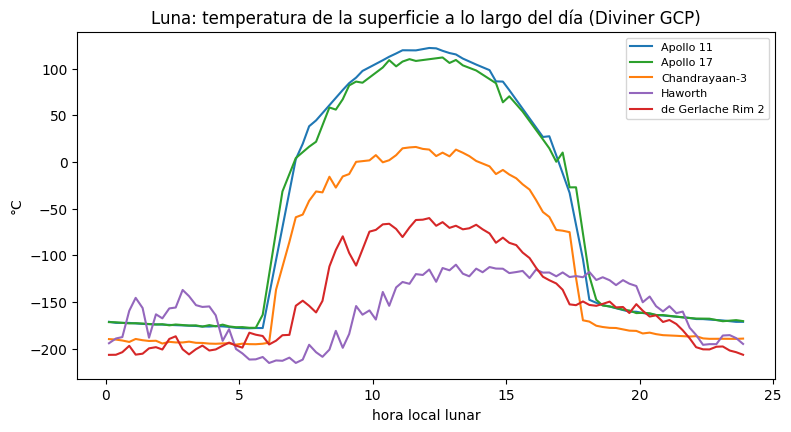

,id,nombre,tipo,ts_media,ts_min,ts_max,osc_diaria,horas_con_dato,celdas_gcp
0,artemis-peak-near-cabeus-b,Peak Near Cabeus B,region_aterrizaje_artemis,-128.0,-220.0,1.5,221.5,96,28
1,artemis-haworth,Haworth,region_aterrizaje_artemis,-156.9,-215.5,-110.1,105.4,96,69
2,artemis-malapert-massif,Malapert Massif,region_aterrizaje_artemis,-127.0,-202.0,-87.2,114.8,96,48
3,artemis-mons-mouton-plateau,Mons Mouton Plateau,region_aterrizaje_artemis,-131.4,-202.7,-36.9,165.8,96,189
4,artemis-mons-mouton,Mons Mouton,region_aterrizaje_artemis,-144.3,-206.7,-81.6,125.0,96,42
5,artemis-nobile-rim-1,Nobile Rim 1,region_aterrizaje_artemis,-132.2,-174.3,-98.4,75.9,96,43
6,artemis-nobile-rim-2,Nobile Rim 2,region_aterrizaje_artemis,-155.0,-216.0,-52.4,163.6,96,32
7,artemis-de-gerlache-rim-2,de Gerlache Rim 2,region_aterrizaje_artemis,-146.2,-206.8,-60.1,146.6,96,79
8,artemis-slater-plain,Slater Plain,region_aterrizaje_artemis,-156.7,-218.4,-72.5,145.9,96,60
9,apollo-11,Apollo 11,aterrizaje_tripulado,-59.6,-178.3,122.3,300.5,64,3


In [35]:
if faltan_gcp:
    raise SystemExit("⏸ Faltan bandas de Diviner: vuelve a ejecutar el notebook.")

gcp = pd.concat([pd.read_csv(p) for p in glob.glob(f"{CACHE_DIV}/gcp_*.csv.gz")], ignore_index=True)
C_LAT, C_LON = columna(gcp.columns, "lat"), columna(gcp.columns, "lon")
C_LT = columna(gcp.columns, "ltim", "local", "lt")
C_TB = columna(gcp.columns, "tbol", "bol")
gcp = gcp[gcp[C_TB] > 0]                       # -9999 = sin dato
print(f"Columnas usadas: lat={C_LAT} lon={C_LON} hora local={C_LT} temperatura={C_TB} · {len(gcp):,} filas")

def dist_km(lat1, lon1, lat2, lon2, R=R_LUNA_KM):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dl = np.radians(lon2 - lon1)
    return R * np.arccos(np.clip(np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl), -1, 1))

celdas_gcp = gcp[[C_LAT, C_LON]].drop_duplicates().to_numpy()
filas, curvas = [], {}
for r in luna.itertuples():
    if r.geom.geom_type != "Point":
        dentro = contains_xy(r.geom, celdas_gcp[:, 1], celdas_gcp[:, 0])
    else:
        dentro = np.zeros(len(celdas_gcp), bool)
    d = dist_km(r.lat, r.lon, celdas_gcp[:, 0], celdas_gcp[:, 1])
    dentro |= d <= RADIO_SITIO_LUNA_KM
    if not dentro.any():
        dentro = d <= d.min() + 1e-6           # la celda más cercana
    sel = pd.MultiIndex.from_arrays([celdas_gcp[dentro, 0], celdas_gcp[dentro, 1]])
    g = gcp.set_index([C_LAT, C_LON]).loc[lambda x: x.index.isin(sel)]
    curva = g.groupby(C_LT)[C_TB].mean().sort_index()  # temperatura media del sitio en cada hora local (K)
    curvas[r.id] = curva
    tc = curva.to_numpy() - 273.15
    filas.append({"id": r.id, "ts_media": tc.mean(), "ts_min": tc.min(), "ts_max": tc.max(), "osc_diaria": tc.max() - tc.min(),
                  "horas_con_dato": len(curva), "celdas_gcp": int(dentro.sum())})
luna = luna.merge(pd.DataFrame(filas), on="id", how="left")
luna["cuerpo"] = "luna"

fig, ax = plt.subplots(figsize=(9, 4.5))
for sid, col in [("apollo-11", "tab:blue"), ("apollo-17", "tab:green"), ("aterrizaje-chandrayaan-3", "tab:orange"), ("artemis-haworth", "tab:purple"), ("artemis-de-gerlache-rim-2", "tab:red")]:
    if sid in curvas:
        ax.plot(curvas[sid].index, curvas[sid].values - 273.15, label=luna.set_index("id").nombre.get(sid, sid), color=col)
ax.set_xlabel("hora local lunar"); ax.set_ylabel("°C"); ax.set_title("Luna: temperatura de la superficie a lo largo del día (Diviner GCP)"); ax.legend(fontsize=8)
plt.show()
display(luna[["id", "nombre", "tipo", "ts_media", "ts_min", "ts_max", "osc_diaria", "horas_con_dato", "celdas_gcp"]].round(1))

### 6b. Luna: hielo y temperaturas del polo sur (Diviner PRP)
El archivo tiene una fila por triángulo de una malla del polo sur (hasta 80°S). Las columnas se leen de su etiqueta PDS; si no aparecen latitud y longitud, el paso se omite y se avisa (no afecta al resto).

In [36]:
prp_salida = f"{CACHE_DIV}/prp_sitios.csv"
U_PRP = "https://pds-geosciences.wustl.edu/lro/urn-nasa-pds-lro_diviner_derived1/data_derived_prp/dlre_prp_south.tab"

# Unidad de la profundidad del hielo, leída de la etiqueta PDS4
xml = requests.get(U_PRP[:-4] + ".xml", timeout=60).text
m_u = re.search(r"<name>\s*ice_depth\s*</name>.*?<unit>(.*?)</unit>", xml, flags=re.S | re.I)
UNIDAD_HIELO = m_u.group(1).strip() if m_u else "sin unidad en la etiqueta"
print("Unidad de ice_depth:", UNIDAD_HIELO)

polo = luna[luna.lat < -75].copy()
geoms_polo = {r.id: (r.geom if r.geom.geom_type != "Point" else circulo_grados(r.lon, r.lat, RADIO_SITIO_LUNA_KM)) for r in polo.itertuples()}

if os.path.exists(prp_salida):
    prp = pd.read_csv(prp_salida)
else:
    acum_prp = {sid: [] for sid in geoms_polo}
    cols = ["tri_clon", "tri_clat", "temp_avg", "temp_max", "ice_depth"]
    for i, t in enumerate(pd.read_csv(U_PRP, skipinitialspace=True, usecols=cols, chunksize=500_000)):
        lo_ = ((t.tri_clon.to_numpy(float) + 180) % 360) - 180
        la = t.tri_clat.to_numpy(float)
        for sid, g in geoms_polo.items():
            dentro = contains_xy(g, lo_, la)
            if dentro.any():
                acum_prp[sid].append(t.loc[dentro, ["temp_avg", "temp_max", "ice_depth"]])
        print(f"  trozo {i + 1} ({minutos():.0f} min)")
    filas = []
    for sid, trozos in acum_prp.items():
        if not trozos:
            continue
        t = pd.concat(trozos)
        h = t.ice_depth[t.ice_depth >= 0]
        filas.append({"id": sid, "triangulos": len(t),
                      "prp_t_media_c": t.temp_avg.mean() - 273.15,
                      "prp_t_max_c": t.temp_max.mean() - 273.15,
                      "frac_hielo_estable": len(h) / len(t),
                      "hielo_prof_mediana": h.median() if len(h) else np.nan})
    prp = pd.DataFrame(filas)
    prp.to_csv(prp_salida, index=False)

luna = luna.drop(columns=[c for c in prp.columns if c != "id" and c in luna.columns]).merge(prp, on="id", how="left")
print(f"Profundidad del hielo en {UNIDAD_HIELO}; frac_hielo_estable = parte del sitio donde el hielo sería estable")
display(prp.round(3))

Unidad de ice_depth: meter
Profundidad del hielo en meter; frac_hielo_estable = parte del sitio donde el hielo sería estable


,id,triangulos,prp_t_media_c,prp_t_max_c,frac_hielo_estable,hielo_prof_mediana
0,artemis-peak-near-cabeus-b,3089,-129.670,6.567,0.292,0.054
1,artemis-haworth,6902,-164.332,-30.784,0.615,0.125
2,artemis-malapert-massif,3467,-128.406,2.259,0.210,0.212
3,artemis-mons-mouton-plateau,34284,-132.632,-13.669,0.194,0.146
4,artemis-mons-mouton,1987,-155.643,-24.642,0.465,0.251
5,artemis-nobile-rim-1,3114,-142.728,-6.125,0.353,0.213
6,artemis-nobile-rim-2,3122,-154.008,-36.992,0.337,0.056
7,artemis-de-gerlache-rim-2,3117,-141.847,-17.009,0.262,0.307
8,artemis-slater-plain,3099,-165.147,-40.852,0.541,0.036
9,aterrizaje-im-1-odysseus,410,-180.240,-25.591,0.968,0.055


## 7. Comparación sitio ↔ Tierra
- Percentil de cada sitio dentro de su cuerpo (los sitios de Marte entre sí, los de la Luna entre sí, como en v0).
- Percentil de cada lugar de la Tierra **frente a toda la tierra emergida** (rejilla de referencia, ponderada por área).
- Distancia de clima = media de las diferencias de percentil (0 a 1) en las 4 medidas del cuerpo.
- Distancia total = media de clima y topografía (`topografia_sitios_v1`). Parecido si ≤ 0,2.
- **Brecha absoluta**: diferencia en °C entre el sitio y su pareja en cada medida.

In [37]:
def percentil(valores_ref, pesos_ref, x):
    ok = np.isfinite(valores_ref)
    v, w = valores_ref[ok], pesos_ref[ok]
    orden = np.argsort(v); v, w = v[orden], np.cumsum(w[orden]) / w.sum()
    i = np.searchsorted(v, x, side="right")
    return np.where(np.isfinite(x), np.where(i > 0, w[np.clip(i - 1, 0, len(w) - 1)], 0.0), np.nan)

pct_tierra = pd.DataFrame({"region_id": tierra.region_id})
for kk in set(sum(MEDIDAS.values(), [])):
    pct_tierra[kk] = percentil(REF[kk].ravel(), W_REF.ravel(), tierra[kk].to_numpy(float))

topo = pd.read_csv(TOPO_SITIOS) if os.path.exists(TOPO_SITIOS) else pd.DataFrame()
if len(topo):
    c_sit = next((c for c in topo.columns if c in ("id", "sitio_id", "id_sitio", "sitio")), None)
    c_dis = next((c for c in topo.columns if c.startswith("distancia")), None)
    if c_sit and c_dis and "region_id" in topo.columns:
        topo = topo.rename(columns={c_sit: "id", c_dis: "dist_topo"})[["id", "region_id", "dist_topo"]]
    else:
        print("⚠️ No reconozco las columnas de", TOPO_SITIOS, list(topo.columns), "→ solo se usa el clima")
        topo = pd.DataFrame()
print("Topografía por pareja:", len(topo), "filas")

def comparar(sitios, cuerpo):
    med = MEDIDAS[cuerpo]
    ps = pd.DataFrame({"id": sitios.id})
    for kk in med:
        v = sitios[kk].to_numpy(float)
        ps[kk] = percentil(v, np.ones_like(v), v)
    filas = []
    for s, ss in zip(ps.itertuples(index=False), sitios.itertuples(index=False)):
        for t, tt in zip(pct_tierra.itertuples(index=False), tierra.itertuples(index=False)):
            difs = [abs(getattr(s, kk) - getattr(t, kk)) for kk in med]
            difs = [x for x in difs if np.isfinite(x)]
            f = {"id": ss.id, "nombre": ss.nombre, "tipo": ss.tipo, "region_id": tt.region_id, "region": tt.region,
                 "cuerpo_perfil": tt.cuerpo, "tipo_tierra": tt.tipo, "dist_clima": np.mean(difs) if len(difs) >= 3 else np.nan}
            for kk in med:
                f[f"brecha_{kk}"] = getattr(ss, kk) - getattr(tt, kk)
            filas.append(f)
    sim = pd.DataFrame(filas)
    if len(topo):
        sim = sim.merge(topo, on=["id", "region_id"], how="left")
        sim["dist_total"] = sim[["dist_clima", "dist_topo"]].mean(axis=1, skipna=False)
    else:
        sim["dist_topo"] = np.nan; sim["dist_total"] = np.nan
    return sim.round(3)

sim_marte, sim_luna = comparar(marte, "marte"), comparar(luna, "luna")

def mejores(sim, col):
    m = sim.dropna(subset=[col]).sort_values(col).groupby("id").head(1).set_index("id")
    return m

for nombre, sim in [("Marte", sim_marte), ("Luna", sim_luna)]:
    n = sim.id.nunique()
    mc, mt = mejores(sim, "dist_clima"), mejores(sim, "dist_total")
    print(f"\n{nombre}: {(mc.dist_clima <= UMBRAL_PARECIDO).sum()}/{n} sitios con pareja por clima · "
          f"{(mt.dist_total <= UMBRAL_PARECIDO).sum()}/{n} por clima + topografía")
    display(mt.sort_values("dist_total")[["nombre", "tipo", "region", "dist_clima", "dist_topo", "dist_total"] +
                                         [c for c in mt.columns if c.startswith("brecha_")]].head(15))

Topografía por pareja: 2737 filas

Marte: 55/59 sitios con pareja por clima · 42/59 por clima + topografía


,nombre,tipo,region,dist_clima,dist_topo,dist_total,brecha_ts_media,brecha_ts_min,brecha_amplitud_anual,brecha_osc_diaria
id,,,,,,,,,,
ez-e-hellas,E. Hellas,exploration_zone,Groenlandia,0.056,0.095,0.076,-52.0,-87.9,35.3,71.9
ez-newton-crater,Newton Crater,exploration_zone,Groenlandia,0.073,0.100,0.087,-50.2,-87.5,34.4,74.1
aterrizaje-viking-2,Viking 2,aterrizaje_robotico,Isla Devon (Haughton-Mars Project),0.030,0.143,0.087,-54.7,-83.2,24.2,68.9
aterrizaje-mars-3,Mars 3,aterrizaje_robotico,Groenlandia,0.073,0.109,0.091,-50.2,-87.5,34.4,74.1
ez-huygens-crater,Huygens Crater,exploration_zone,"Provincia Oriental, Arabia Saudita",0.120,0.078,0.099,-82.1,-106.9,9.0,67.2
ez-copernicus-crater,Copernicus Crater,exploration_zone,Groenlandia,0.051,0.168,0.109,-57.4,-89.6,54.7,59.2
ez-kasei-valles,Kasei Valles,exploration_zone,"Región de Antofagasta, Chile",0.157,0.069,0.113,-80.8,-108.5,2.8,81.1
ez-deuteronilus-mensae-2,Deuteronilus Mensae 2,exploration_zone,Groenlandia,0.187,0.057,0.122,-49.3,-79.3,5.0,77.7
ez-jezero-isidis-syrtis,Jezero-Isidis-Syrtis,exploration_zone,Lanzarote (ESA PANGAEA),0.124,0.124,0.124,-76.0,-101.3,4.5,72.4



Luna: 37/38 sitios con pareja por clima · 14/38 por clima + topografía


,nombre,tipo,region,dist_clima,dist_topo,dist_total,brecha_ts_media,brecha_ts_min,brecha_ts_max,brecha_osc_diaria
id,,,,,,,,,,
aterrizaje-surveyor-6,Surveyor 6,aterrizaje_robotico,"Provincia de La Meca, Arabia Saudita",0.106,0.068,0.087,-91.260,-190.228,68.924,272.952
aterrizaje-surveyor-5,Surveyor 5,aterrizaje_robotico,"Provincia de La Meca, Arabia Saudita",0.022,0.155,0.089,-84.027,-189.565,69.306,272.671
apollo-16,Apollo 16,aterrizaje_tripulado,Lanzarote – Timanfaya,0.080,0.104,0.092,-91.715,-191.722,75.648,275.270
apollo-11,Apollo 11,aterrizaje_tripulado,"Provincia de Medina, Arabia Saudita",0.116,0.102,0.109,-91.184,-185.767,64.876,271.542
aterrizaje-luna-16,Luna 16,aterrizaje_robotico,"Provincia de La Meca, Arabia Saudita",0.115,0.111,0.113,-90.182,-188.954,69.759,272.513
aterrizaje-luna-20,Luna 20,aterrizaje_robotico,Irán,0.138,0.094,0.116,-89.086,-185.359,64.283,273.543
apollo-14,Apollo 14,aterrizaje_tripulado,Lanzarote – Timanfaya,0.086,0.170,0.128,-81.846,-190.195,79.660,277.755
aterrizaje-luna-9,Luna 9,aterrizaje_robotico,"Provincia de Tabuk, Arabia Saudita",0.125,0.133,0.129,-90.628,-189.168,63.477,271.245
aterrizaje-luna-23,Luna 23,aterrizaje_robotico,"Gobernacion de Rif Dimashq, Siria",0.149,0.110,0.130,-92.049,-180.856,63.226,270.782


## 8. Validación con los análogos conocidos
Un análogo conocido de Marte (o de la Luna) debería parecerse por clima al menos a un sitio de su cuerpo.

In [38]:
val = []
for cuerpo, sim in [("marte", sim_marte), ("luna", sim_luna)]:
    a = sim[(sim.tipo_tierra == "analogo_conocido") & (sim.cuerpo_perfil == cuerpo)].dropna(subset=["dist_clima"])
    for rid, g in a.groupby("region_id"):
        b = g.sort_values("dist_clima").iloc[0]
        val.append({"cuerpo": cuerpo, "analogo": b.region, "mejor_sitio": b.nombre, "dist_clima": b.dist_clima,
                    "sitios_parecidos": int((g.dist_clima <= UMBRAL_PARECIDO).sum()), "parecido": b.dist_clima <= UMBRAL_PARECIDO})
val = pd.DataFrame(val, columns=["cuerpo", "analogo", "mejor_sitio", "dist_clima", "sitios_parecidos", "parecido"])
for cuerpo, g in val.groupby("cuerpo"):
    print(f"{cuerpo}: {g.parecido.sum()}/{len(g)} análogos conocidos se parecen por clima al menos a un sitio")
display(val.sort_values(["cuerpo", "dist_clima"]))

# Cambio respecto a v0 en Marte (solo clima + topografía)
p_v0 = f"{CLIMA_V0}/clima_topografia_sitios_marte.csv"
if os.path.exists(p_v0):
    v0m = pd.read_csv(p_v0)
    c_v0 = next((c for c in v0m.select_dtypes("number").columns if "total" in c), None)
    if c_v0:
        print(f"Marte v0: {(v0m[c_v0] <= UMBRAL_PARECIDO).sum()}/{len(v0m)} con pareja (clima + topografía)")

luna: 7/7 análogos conocidos se parecen por clima al menos a un sitio
marte: 8/8 análogos conocidos se parecen por clima al menos a un sitio


,cuerpo,analogo,mejor_sitio,dist_clima,sitios_parecidos,parecido
11,luna,Lanzarote – Timanfaya,Luna 24,0.039,17,True
10,luna,"Kīlauea, Hawái",Blue Ghost M1,0.054,17,True
8,luna,"Askja, Islandia",Mons Mouton,0.063,13,True
14,luna,"Pinacate, Sonora",Luna 9,0.068,14,True
13,luna,"Meteor Crater, Arizona",Surveyor 6,0.123,6,True
12,luna,"Mauna Kea, Hawái",Apollo 16,0.134,7,True
9,luna,"Craters of the Moon, Idaho",Luna 17,0.159,8,True
2,marte,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),Viking 2,0.022,13,True
3,marte,Isla Devon (Haughton-Mars Project),Viking 2,0.030,13,True
7,marte,Valles Secos de McMurdo,Viking 2,0.057,11,True


Marte v0: 42/59 con pareja (clima + topografía)


## 9. Exportación

In [39]:
os.makedirs(RES, exist_ok=True)
tierra.to_csv(f"{RES}/clima_tierra_superficie.csv", index=False)
marte.to_csv(f"{RES}/clima_marte_sitios.csv", index=False)
luna.drop(columns="geom").to_csv(f"{RES}/clima_luna_sitios.csv", index=False)
sim_marte.to_csv(f"{RES}/similitud_clima_marte.csv", index=False)
sim_luna.to_csv(f"{RES}/similitud_clima_luna.csv", index=False)
val.to_csv(f"{RES}/validacion_analogos.csv", index=False)
pd.DataFrame({c: curvas[c] for c in curvas}).to_csv(f"{RES}/curvas_diurnas_luna_K.csv")

def limpio(v):
    if isinstance(v, (float, np.floating)):
        return None if not np.isfinite(v) else round(float(v), 3)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    return v

salida = {"version": VERSION, "generado": datetime.datetime.now().isoformat(timespec="seconds"),
          "medidas": MEDIDAS, "umbral_parecido": UMBRAL_PARECIDO,
          "unidades": "°C; distancias de 0 (igual) a 1",
          "tierra": {r.region_id: {k: limpio(getattr(r, k)) for k in ["region", "cuerpo", "tipo", "ts_media", "ts_min", "ts_max", "amplitud_anual", "osc_diaria"]}
                     for r in tierra.itertuples()},
          "sitios": {}}
for cuerpo, sit, sim in [("marte", marte, sim_marte), ("luna", luna, sim_luna)]:
    for r in sit.itertuples():
        g = sim[sim.id == r.id]
        orden = "dist_total" if g.dist_total.notna().any() else "dist_clima"
        top = g.dropna(subset=[orden]).sort_values(orden).head(5)
        extra = {k: limpio(getattr(r, k)) for k in ("prp_t_media_c", "prp_t_max_c", "hielo_prof_mediana", "frac_hielo_estable") if hasattr(r, k)}
        salida["sitios"][r.id] = {"nombre": r.nombre, "cuerpo": cuerpo, "tipo": r.tipo,
                                  **{k: limpio(getattr(r, k)) for k in ["ts_media", "ts_min", "ts_max", "amplitud_anual", "osc_diaria"] if hasattr(r, k)},
                                  **extra,
                                  "parejas": [{k: limpio(v) for k, v in p.items() if k in ("region_id", "region", "dist_clima", "dist_topo", "dist_total") or k.startswith("brecha_")}
                                              for p in top.to_dict("records")],
                                  "hay_parecido": bool(len(top) and top.iloc[0][orden] <= UMBRAL_PARECIDO)}
json.dump(salida, open(f"{WEB}/clima.json", "w", encoding="utf-8"), ensure_ascii=False)

registro = {"version": VERSION, "fecha": salida["generado"],
            "datos": {"tierra": f"NASA MODIS Aqua {PRODUCTO_LST} v{VERSION_LST} (doi:10.5067/MODIS/MYD11C3.061), {ANIOS[0]}–{ANIOS[-1]}",
                      "marte": "MACDA v2.0 en ARCO-Mars (de clima_v0)",
                      "luna": "LRO Diviner GCP (Williams et al. 2017, doi:10.1016/j.icarus.2016.08.012) y PRP (Paige et al. 2010, doi:10.1126/science.1187726); PDS4 lro_diviner_derived1 (doi:10.17189/wj0s-w188)"},
            "parametros": {"medidas": MEDIDAS, "paso_ref_celdas": PASO_REF, "min_meses": MIN_MESES, "radio_sitio_luna_km": RADIO_SITIO_LUNA_KM, "umbral_parecido": UMBRAL_PARECIDO},
            "resultados": {"marte_clima": int((mejores(sim_marte, "dist_clima").dist_clima <= UMBRAL_PARECIDO).sum()),
                           "marte_total": int((mejores(sim_marte, "dist_total").dist_total <= UMBRAL_PARECIDO).sum()) if sim_marte.dist_total.notna().any() else None,
                           "luna_clima": int((mejores(sim_luna, "dist_clima").dist_clima <= UMBRAL_PARECIDO).sum()),
                           "luna_total": int((mejores(sim_luna, "dist_total").dist_total <= UMBRAL_PARECIDO).sum()) if sim_luna.dist_total.notna().any() else None,
                           "analogos_validados": f"{int(val.parecido.sum())}/{len(val)}"},
            "limitaciones": [
                "MODIS Aqua solo ve el cielo despejado y pasa a las 13:30 y 01:30: la mínima real (al amanecer) es algo más fría que la de las 01:30",
                "la órbita de Aqua se ha ido desplazando desde 2022 (pasa algo más tarde)",
                "la comparación es relativa (percentiles): la Luna y Marte son mucho más extremos que cualquier lugar de la Tierra; las brechas en °C lo muestran",
                "Marte en celdas de 5° (MACDA) y la Luna en celdas de 0,5° (~15 km): un cráter pequeño recibe la temperatura de toda la celda",
                "Diviner GCP mezcla todas las estaciones (2009–2015): en el polo sur la máxima de verano y la de invierno difieren mucho",
                "los sitios de Marte y la Luna se comparan entre sí (percentil dentro de los sitios), no frente a todo el cuerpo",
                "la Luna no tiene estaciones apreciables: se usa la máxima en lugar de la amplitud anual"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

manifest = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
manifest.setdefault("capas", {})["clima"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/clima.json"}
json.dump(manifest, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("✅ Exportado:", RES, "y", f"{WEB}/clima.json")
print(json.dumps(registro["resultados"], ensure_ascii=False, indent=1))

✅ Exportado: /content/drive/MyDrive/Hackathon Nasa/04_resultados/clima_v1 y /content/drive/MyDrive/Hackathon Nasa/06_web/clima_v1/clima.json
{
 "marte_clima": 55,
 "marte_total": 42,
 "luna_clima": 37,
 "luna_total": 14,
 "analogos_validados": "15/15"
}
